In [1]:
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
import torch.nn.functional as F

In [2]:
def beta_crit(d, s0):
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0
n=300
eta=0.01
decay_rate=0.015
Lx=32
s0 = (n*eta)/(decay_rate*Lx**2)

In [3]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import Normalize
def plot_results(res, beta_list, delta_list, cmap='summer', column_name='pop'):

    fig = plt.figure(figsize=(8,8), constrained_layout=True)
    gs = GridSpec(len(beta_list), len(delta_list), figure=fig)
    
    if column_name == 'pod' or column_name == 'pop':
        vmin, vmax = -1, 1

    elif column_name == 'reward difference':
        vmin, vmax = -2, 2
        
    elif column_name == 'original':
        vmin, vmax = np.min(res), np.max(res)
        
    else:
        vmin, vmax = -1, 0

        
    norm = Normalize(vmin=vmin, vmax=vmax)

    ax = np.empty((len(beta_list), len(delta_list)), dtype=object)
    for i in range(len(beta_list)):
        for j in range(len(delta_list)):
            ax[i, j] = fig.add_subplot(gs[i, j])
            img = ax[i, j].imshow(
                np.ones((1, 1)) * res[len(beta_list)-i-1, j],
                cmap=cmap,
                norm=norm
            )
            ax[i, j].set_xticks([])
            ax[i, j].set_yticks([])

            if j == 0:
                ax[i, j].set_ylabel(f'{beta_list[len(beta_list)-i-1]}', fontsize=15)
            if i == len(beta_list)-1:
                ax[i, j].set_xlabel(f'{delta_list[j]}', fontsize=15)

    # Overlay curve axis
    ax_curve = fig.add_subplot(gs[:, :], frameon=False)
    ax_curve.plot(
        delta_list,
        [beta_crit(d, s0) for d in delta_list],
        color='red', linestyle='--', linewidth=2
    )
    ax_curve.set_xlim(min(delta_list), max(delta_list))
    ax_curve.set_ylim(min(beta_list), max(beta_list))
    ax_curve.set_xticks([])
    ax_curve.set_yticks([])
    
    # Shared colorbar
    cbar = fig.colorbar(img, ax=ax.ravel().tolist(), shrink=0.8, pad=0.1)

    # Global labels
    fig.text(-0.05, 0.52, r'$\beta$', fontsize=20, va='center', rotation='vertical')
    fig.text(0.42, -0.03, r'$\delta$', fontsize=20, ha='center')
    '''fig.text(0.42, 1.02, f'{op_name} order parameter', fontsize=12, ha='center')'''

    plt.show()

In [4]:
# load the dataset
import pandas as pd
dfbm_rand = pd.read_csv("Ants_move_rand/PPO/edge_spen/benchmark_results_notreset.csv")
dfbm = pd.read_csv("Ants_move/PPO/edge_spen/benchmark_results_bd.csv")
dfbm_30 = pd.read_csv("Ants_move/PPO/ants_move_special_300_30.csv")
dfbm_alone = pd.read_csv("Ants_move/PPO/abm_ants_alone_bd.csv")

In [5]:
delta_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta_list = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]

In [6]:
def compute_stats(dfbm, column_name):
    raw_mean_df = dfbm.groupby(['n_special', 'beta', 'delta'])[column_name].mean().unstack().unstack()
    std_mean_df = dfbm.groupby(['n_special', 'beta', 'delta'])[column_name].std().unstack().unstack()

    if dfbm.equals(dfbm_alone):
        raw_mean_df30 = raw_mean_df.loc[1]
        std_mean_df30 = std_mean_df.loc[1]
    else:
        raw_mean_df30 = raw_mean_df.loc[30]
        std_mean_df30 = std_mean_df.loc[30]
        
    raw_mean_arr30 = np.array(raw_mean_df30.values).reshape(len(delta_list), len(beta_list))
    std_mean_arr30 = np.array(std_mean_df30.values).reshape(len(delta_list), len(beta_list))

    return raw_mean_arr30, std_mean_arr30

In [12]:
def plot_results_numbers(res, beta_list, delta_list, column_name='pop', fmt='{:.2f}', show_curve=True):
    fig = plt.figure(figsize=(8, 8), constrained_layout=True)
    gs = GridSpec(len(beta_list), len(delta_list), figure=fig)

    ax = np.empty((len(beta_list), len(delta_list)), dtype=object)
    for i in range(len(beta_list)):
        for j in range(len(delta_list)):
            ax[i, j] = fig.add_subplot(gs[i, j])

            value = float(res[res.shape[0] - i - 1, j])

            # White box with black border
            ax[i, j].imshow(np.ones((1, 1)), cmap='gray', vmin=0, vmax=1)
            for spine in ax[i, j].spines.values():
                spine.set_edgecolor('black')
                spine.set_linewidth(1.2)

            # Number inside the box
            ax[i, j].text(
                0, 0, fmt.format(value),
                ha='center', va='center', fontsize=11, color='black', fontweight='bold'
            )

            ax[i, j].set_xticks([])
            ax[i, j].set_yticks([])

            if j == 0:
                ax[i, j].set_ylabel(f'{beta_list[len(beta_list) - i - 1]}', fontsize=15)
            if i == len(beta_list) - 1:
                ax[i, j].set_xlabel(f'{delta_list[j]}', fontsize=15)

    if show_curve:
        ax_curve = fig.add_subplot(gs[:, :], frameon=False)
        ax_curve.plot(
            delta_list,
            [beta_crit(d, s0) for d in delta_list],
            color='red', linestyle='--', linewidth=2
        )
        ax_curve.set_xlim(min(delta_list), max(delta_list))
        ax_curve.set_ylim(min(beta_list), max(beta_list))
        ax_curve.set_xticks([])
        ax_curve.set_yticks([])

    fig.text(-0.05, 0.52, r'$\beta$', fontsize=20, va='center', rotation='vertical')
    fig.text(0.42, -0.03, r'$\delta$', fontsize=20, ha='center')

    plt.show()

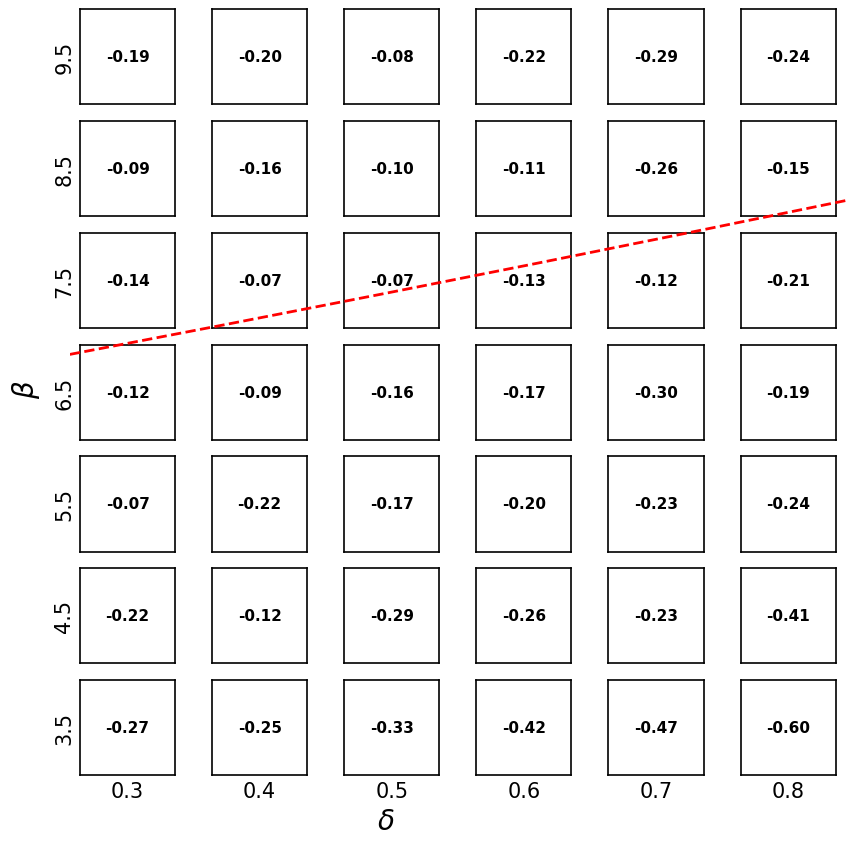

In [26]:
column_name = 'lastr_mean'
res_rand, _ = compute_stats(dfbm_rand, column_name)
plot_results_numbers(res_rand.T, beta_list, delta_list, column_name='pod', fmt='{:.2f}')

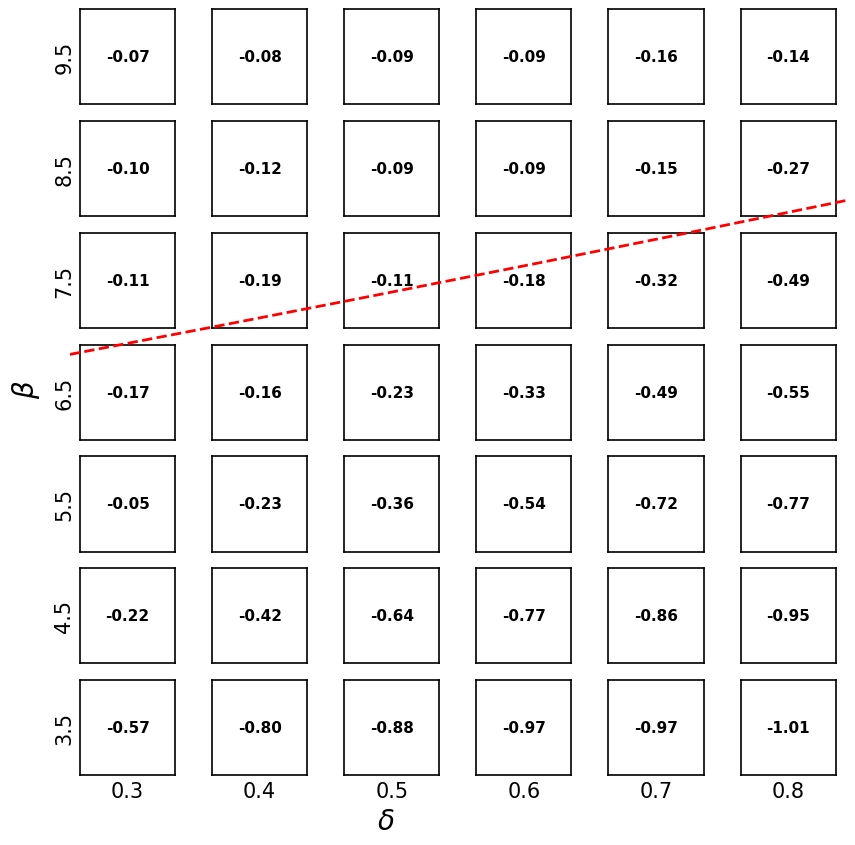

In [27]:
column_name = 'lastr_mean'
res_rand, _ = compute_stats(dfbm_30, column_name)
plot_results_numbers(res_rand.T, beta_list, delta_list, column_name='pod', fmt='{:.2f}')

In [9]:
res_rand

array([[-0.26748109, -0.21634542, -0.06523711, -0.11591012, -0.13562246,
        -0.09486572, -0.19339441],
       [-0.25248492, -0.12140368, -0.22182349, -0.08605908, -0.06528171,
        -0.16400577, -0.20267085],
       [-0.33090964, -0.29098062, -0.17110715, -0.15985224, -0.06895957,
        -0.09963437, -0.08202589],
       [-0.42126719, -0.26329903, -0.20297023, -0.17297173, -0.12535767,
        -0.11130445, -0.21582197],
       [-0.47379352, -0.23011093, -0.22572188, -0.29646219, -0.12024979,
        -0.25508514, -0.28726345],
       [-0.59918997, -0.40732934, -0.23863083, -0.19479315, -0.2078384 ,
        -0.15219937, -0.23663823]])

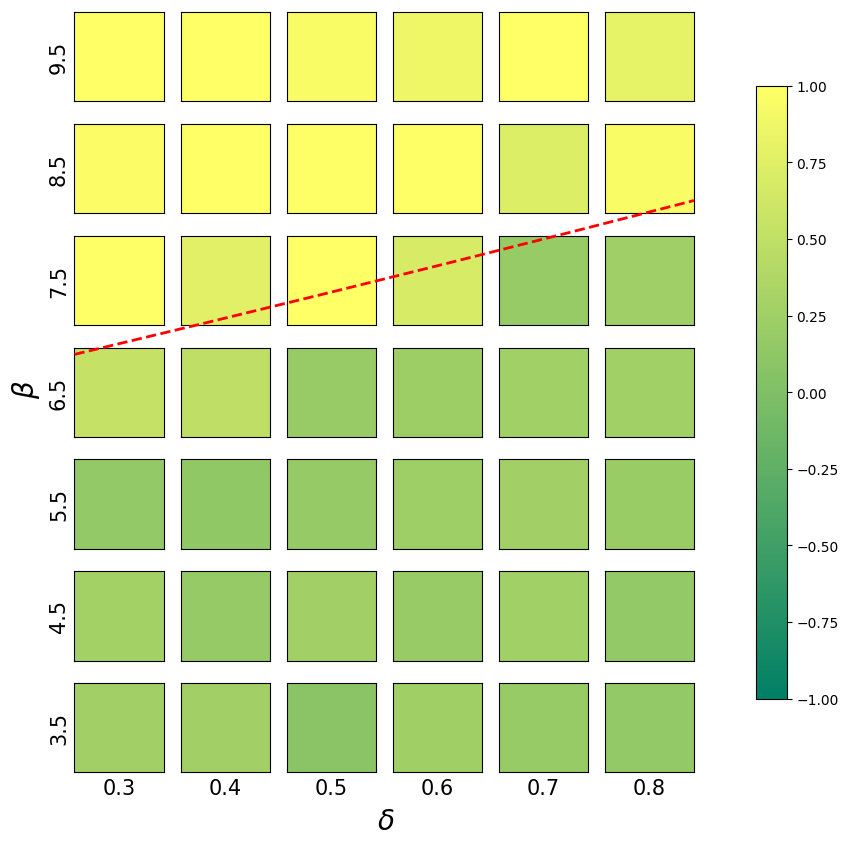

In [17]:
column_name = 'pod'
mean_rand, std_rand = compute_stats(dfbm_alone, column_name)
plot_results(mean_rand.T, beta_list, delta_list, cmap='summer', column_name=column_name)

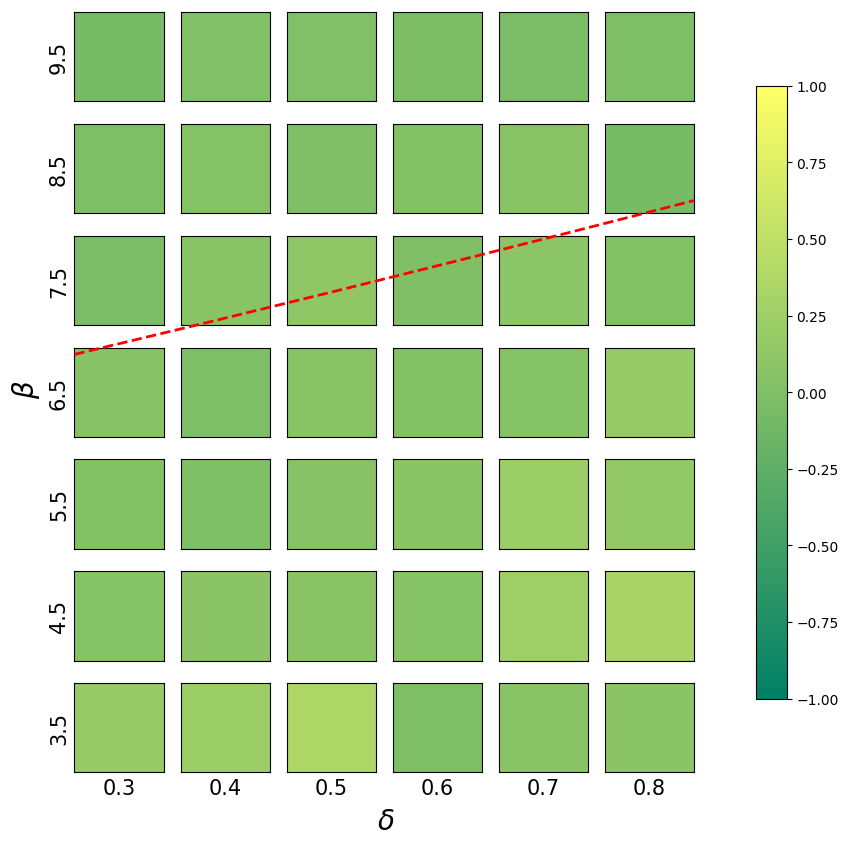

In [56]:
column_name = 'pod'
mean_rand, std_rand = compute_stats(dfbm_rand, column_name)
mean, std = compute_stats(dfbm, column_name)

res = mean_rand.T - mean.T

plot_results(res, beta_list, delta_list, cmap='summer', column_name='pod')

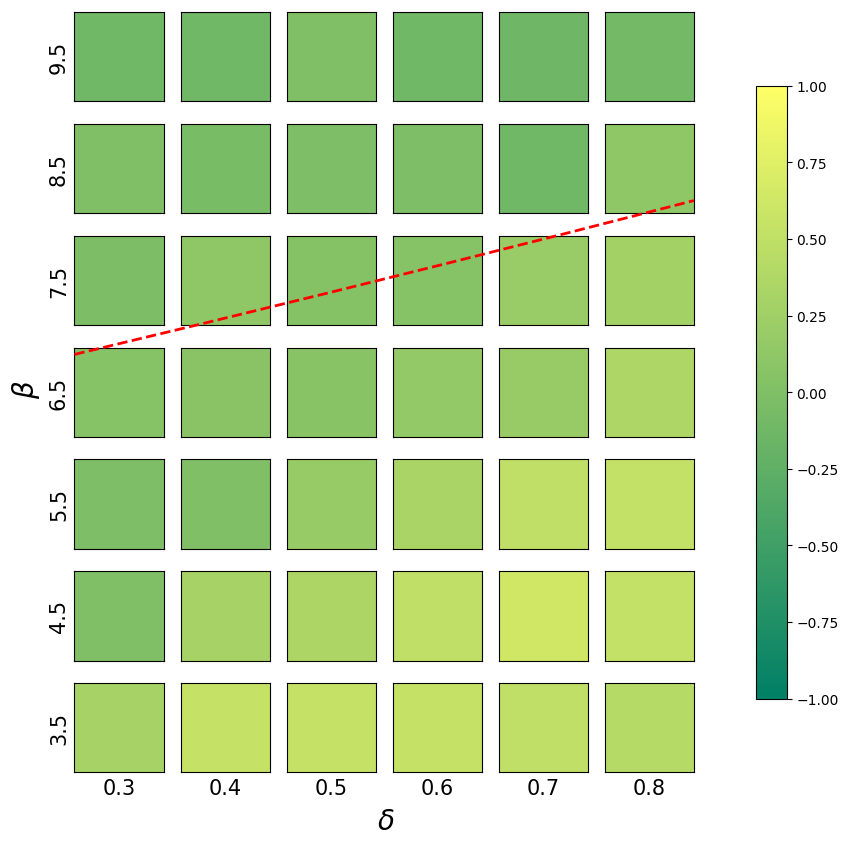

In [49]:
column_name = 'lastr_mean'
mean_rand, std_rand = compute_stats(dfbm_rand, column_name)
mean, std = compute_stats(dfbm_30, column_name)

res = mean_rand.T - mean.T

plot_results(res, beta_list, delta_list, cmap='summer', column_name='pod')

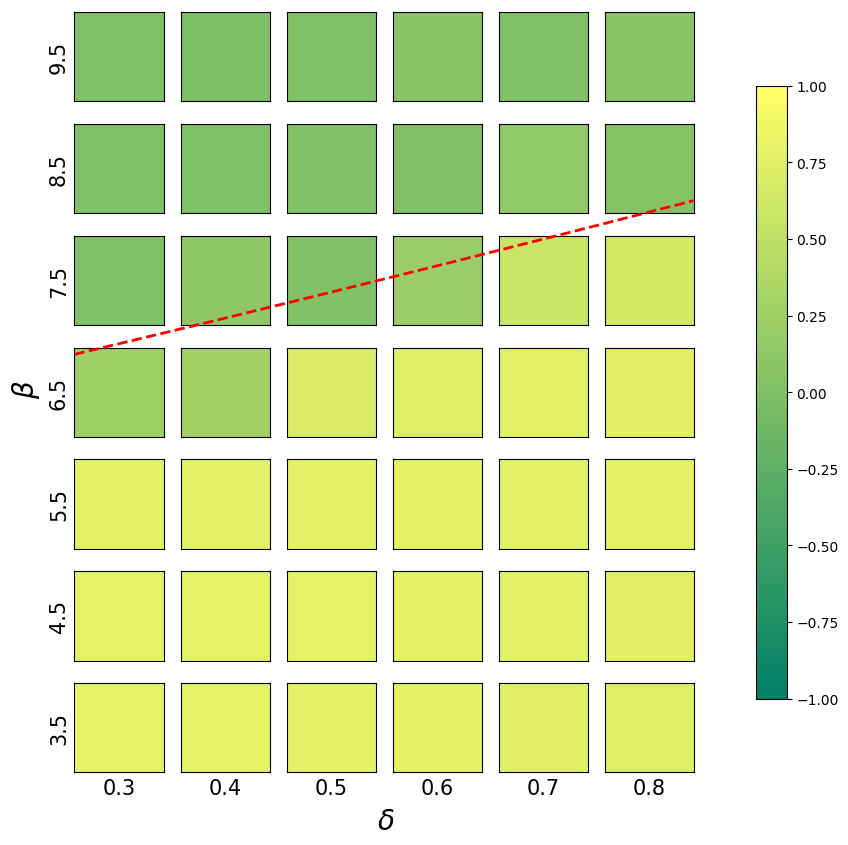

In [51]:
column_name = 'pop'
mean, std = compute_stats(dfbm, column_name)
mean_al, std_al = compute_stats(dfbm_alone, column_name)

res = mean.T - mean_al.T

plot_results(res, beta_list, delta_list, cmap='summer', column_name='pop')

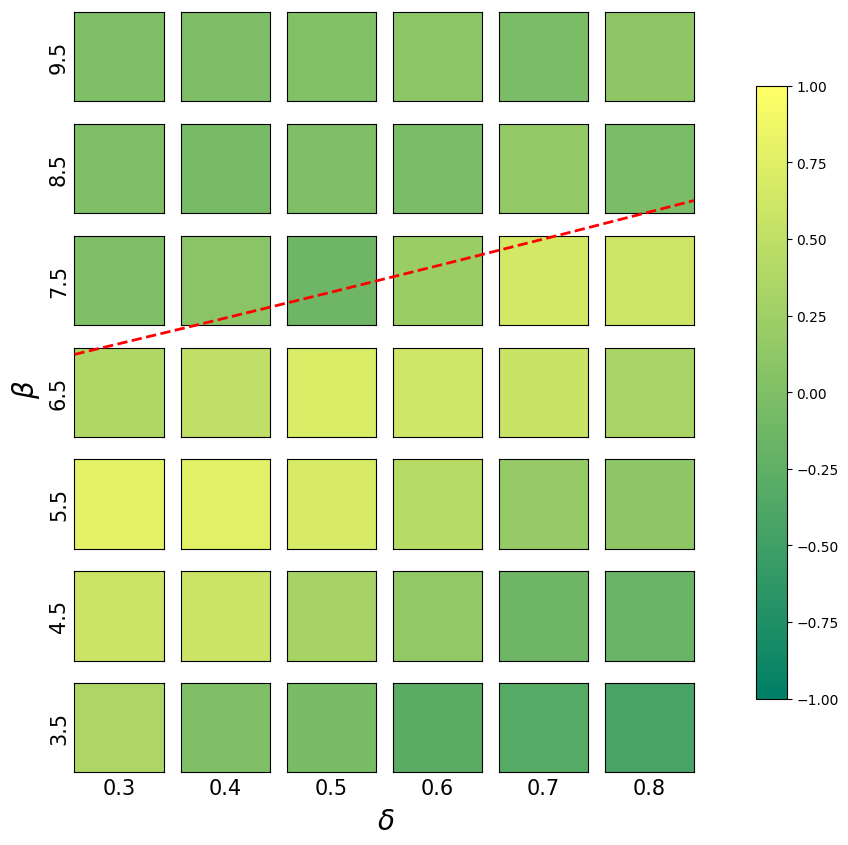

In [57]:
column_name = 'pod'
mean_rand, std_rand = compute_stats(dfbm, column_name)
mean_al, std_al = compute_stats(dfbm_alone, column_name)

res = mean_rand.T - mean_al.T

plot_results(res, beta_list, delta_list, cmap='summer', column_name='pod')

In [20]:
dfbm_rand

,seed,sim_seed,n_special,beta,delta,pop,pod,rew_mean,lastr_mean
0,0,0,5,3.5,0.3,0.830842,0.253333,-0.696660,-0.182633
1,0,1,5,3.5,0.4,0.818456,0.133333,-0.762422,-0.456246
2,0,2,5,3.5,0.5,0.726679,-0.433333,-0.610363,-0.393523
3,0,3,5,3.5,0.6,0.702534,-0.580000,-0.752049,-0.513538
4,0,4,5,3.5,0.7,0.686747,-0.573333,-0.773294,-0.559769
...,...,...,...,...,...,...,...,...,...
2095,9,37,60,9.5,0.4,0.513855,0.693333,-1.604988,-1.769467
2096,9,38,60,9.5,0.5,0.795124,0.600000,-1.393166,-0.993442
2097,9,39,60,9.5,0.6,0.578967,0.640000,-1.522130,-1.504960
2098,9,40,60,9.5,0.7,0.501892,0.433333,-1.794280,-1.875954


In [27]:
dfbm_rand.groupby(['n_special']).agg(['mean', 'std']).drop(columns=['sim_seed', 'beta', 'delta', 'seed'])

pop                 pod            rew_mean            \
               mean       std      mean       std      mean       std   
n_special                                                               
5          0.916414  0.116348  0.740968  0.399597 -0.439984  0.352726   
10         0.940212  0.095385  0.746762  0.390538 -0.414363  0.327121   
15         0.961272  0.066116  0.759254  0.388882 -0.376337  0.270891   
30         0.979965  0.030550  0.762794  0.387364 -0.376435  0.229236   
60         0.934454  0.132111  0.691492  0.393356 -0.575559  0.453147   

          lastr_mean            
                mean       std  
n_special                       
5          -0.334829  0.395752  
10         -0.296432  0.355868  
15         -0.224948  0.275120  
30         -0.210580  0.247722  
60         -0.431984  0.525408

In [28]:
dfbm.groupby(['seed']).agg(['mean', 'std']).drop(columns=['sim_seed', 'n_special', 'beta', 'delta']).agg(['mean'])

pop              pod            rew_mean           lastr_mean  \
          mean     std     mean       std      mean       std       mean   
mean  0.950614  0.0705  0.69674  0.386309 -0.415872  0.226459  -0.246774   

                
           std  
mean  0.237311

In [32]:
dfbm_rand.drop(columns=['sim_seed', 'n_special', 'beta', 'delta', 'seed']).agg(['mean', 'std']).style.format("{:.2f}")

,pop,pod,rew_mean,lastr_mean
mean,0.95,0.74,-0.44,-0.30
std,0.10,0.39,0.34,0.38


In [28]:
# load the dataset
dfbm4507_rand = pd.read_csv("Ants_move_rand/PPO/edge_spen/benchmark_results_b45_d07_rand.csv")
dfbm4507 = pd.read_csv("Ants_move/PPO/edge_spen/benchmark_results_b45_d07.csv")

In [30]:
dfbm4507_rand.groupby(['n_special']).agg(['mean', 'std']).drop(columns=['sim_seed', 'seed', 'beta', 'delta'])

pop                 pod            rew_mean           \
               mean       std      mean       std      mean      std   
n_special                                                              
30         0.951308  0.041157  0.306084  0.370558 -0.527956  0.21934   

          lastr_mean            
                mean       std  
n_special                       
30         -0.346253  0.211265

In [33]:
dfbm4507.groupby(['n_special']).agg(['mean', 'std']).drop(columns=['sim_seed', 'seed'])

pop_mean           pod_mean            rew_mean            \
               mean      std      mean       std      mean       std   
n_special                                                              
30         0.949674  0.02151  0.144422  0.370568 -0.511167  0.187161   

          lastr_mean            
                mean       std  
n_special                       
30         -0.338469  0.200054